# gm/ID Sweeps over Several Dimensions

Ways to visualize pygmid lookups over two or more sweep variables (gm/ID, L, VDS, ...).
Every section shows the same kind of data in a different form.

# Imports and Data Tables

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from pygmid import Lookup as lk

lv_nmos = lk('data/sg13cmos5l_lv_nmos.mat')
lv_pmos = lk('data/sg13cmos5l_lv_pmos.mat')
dev = lv_nmos      # device for all plots below
dev_name = 'LV NMOS'


# Round contour levels (steps of 1, 2 or 5 times a power of ten) over the range of z
def nice_levels(z, n=15):
    return MaxNLocator(n, steps=[1, 2, 5, 10]).tick_values(np.nanmin(z), np.nanmax(z))


# Frequency with unit prefix, for contour labels
def fmt_hz(f):
    for div, unit in ((1e9, 'GHz'), (1e6, 'MHz'), (1e3, 'kHz')):
        if f >= div:
            return f'{f/div:g} {unit}'
    return f'{f:g} Hz'

# Sweep Axes

The tables contain L = 0.13, 0.2, 0.3, 0.4, 0.5, 1, 5, 10, 15, 20, 40 µm only,
everything in between (especially 1 to 5 µm) is linearly interpolated.
gm/ID reaches about 27 S/A at minimum L, so 4 to 25 S/A is covered for every L.

In [2]:
gm_id = np.linspace(4, 25, 85)       # [S/A]
L = np.geomspace(0.13, 10, 60)       # [µm]
VDS = 0.75                           # [V], used for the 2D plots

# With gm/ID as input (mode 3), pygmid returns an array of shape (len(L), len(gm_id))
gain = dev.lookup('GM_GDS', GM_ID=gm_id, L=L, VDS=VDS)             # intrinsic gain [V/V]
fT = dev.lookup('GM_CGG', GM_ID=gm_id, L=L, VDS=VDS) / (2*np.pi)   # transit frequency [Hz]
id_w = dev.lookup('ID_W', GM_ID=gm_id, L=L, VDS=VDS)               # current density [A/µm]

X, Y = np.meshgrid(gm_id, L)   # grid with the same shape as the tables
print(gain.shape, fT.shape, id_w.shape)

(60, 85) (60, 85) (60, 85)


# 1. Contour Plot: One Quantity over Two Sweep Variables

`contourf` fills the areas between levels, `contour` draws lines, `clabel` writes the values onto the lines.

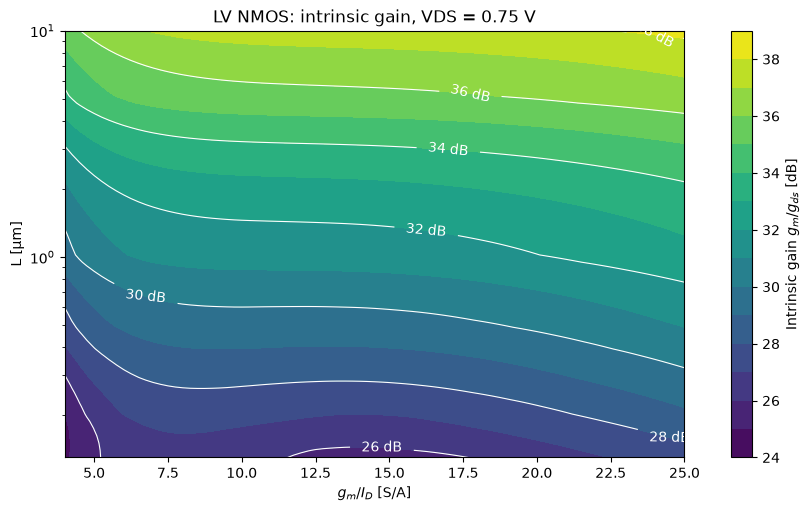

In [3]:
gain_dB = 20*np.log10(gain)

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
cf = ax.contourf(X, Y, gain_dB, levels=nice_levels(gain_dB), cmap='viridis')
fig.colorbar(cf, ax=ax, label='Intrinsic gain $g_m/g_{ds}$ [dB]')
cs = ax.contour(X, Y, gain_dB, levels=cf.levels[::2], colors='white', linewidths=0.8)
ax.clabel(cs, fmt='%g dB')
ax.set(xlabel='$g_m/I_D$ [S/A]', ylabel='L [µm]', yscale='log',
       title=f'{dev_name}: intrinsic gain, VDS = {VDS} V')
plt.show()

# 2. Design Chart: Several Quantities Overlaid

Filled: intrinsic gain, white lines: transit frequency $f_T$, red: region that meets both specs.
The two specs are placeholders, set them from your design (e.g. gain per stage, $f_T \approx 10 \cdot f_{ug}$).

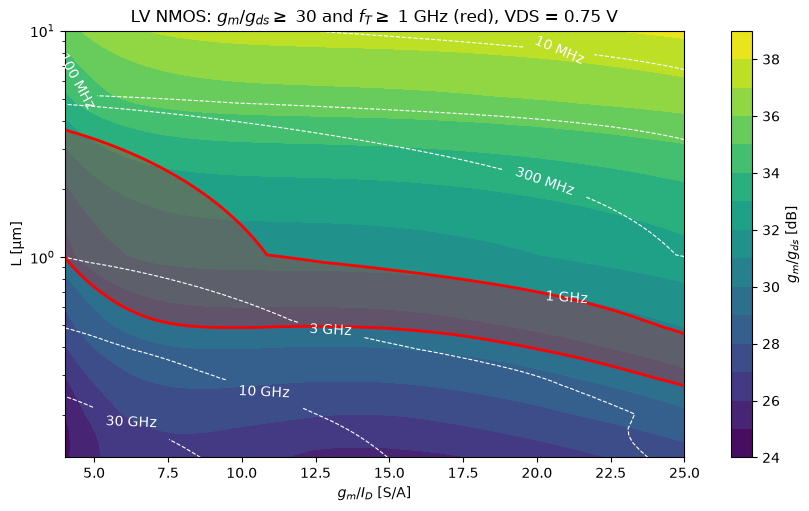

In [4]:
gain_min = 30      # [V/V], placeholder
fT_min = 1e9       # [Hz], placeholder
# >= 1 where both specs are met; a continuous function gives a smooth border, a True/False mask a jagged one
margin = np.minimum(gain/gain_min, fT/fT_min)

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
cf = ax.contourf(X, Y, gain_dB, levels=nice_levels(gain_dB), cmap='viridis')
fig.colorbar(cf, ax=ax, label='$g_m/g_{ds}$ [dB]')
cs = ax.contour(X, Y, fT, levels=[1e7, 1e8, 3e8, 1e9, 3e9, 1e10, 3e10], colors='white', linewidths=0.8, linestyles='--')
ax.clabel(cs, fmt=fmt_hz)
ax.contourf(X, Y, margin, levels=[1, margin.max() + 1], colors='red', alpha=0.25)
ax.contour(X, Y, margin, levels=[1], colors='red', linewidths=2)
ax.set(xlabel='$g_m/I_D$ [S/A]', ylabel='L [µm]', yscale='log',
       title=f'{dev_name}: $g_m/g_{{ds}} \\geq$ {gain_min} and $f_T \\geq$ {fT_min/1e9:g} GHz (red), VDS = {VDS} V')
plt.show()

# 3. Family of Curves: One Sweep Variable as Parameter

The classic gm/ID chart: one curve per L. Exact values are easier to read than in a contour plot,
but only for the few L that are drawn.

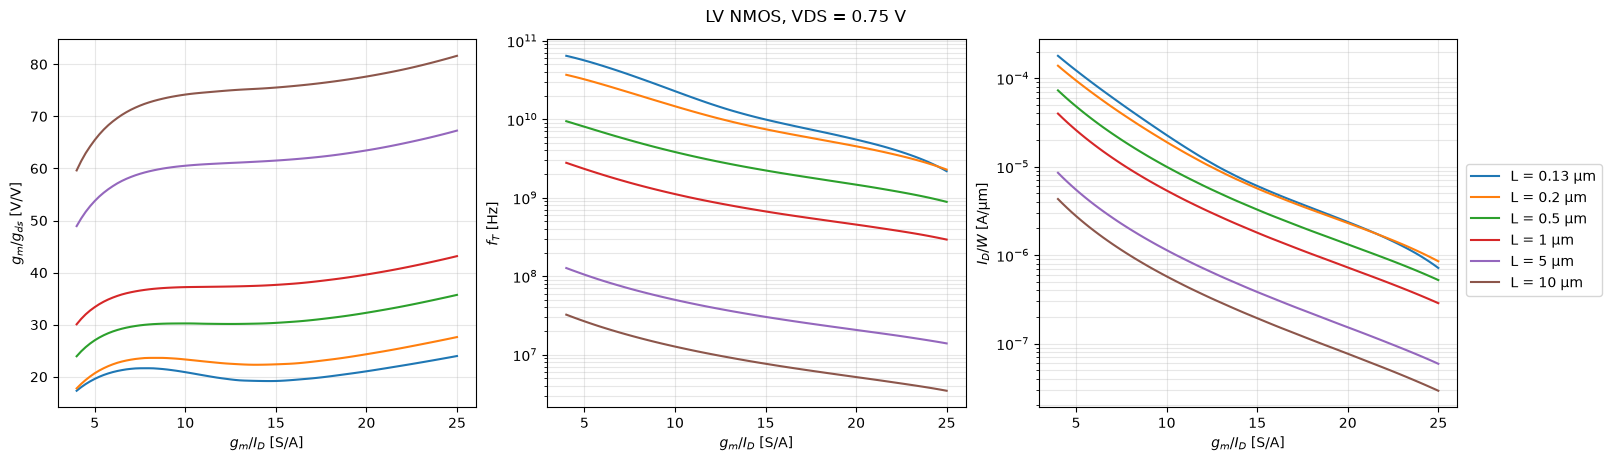

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), layout='constrained')
for l in [0.13, 0.2, 0.5, 1, 5, 10]:    # L values on the table grid
    axs[0].plot(gm_id, dev.lookup('GM_GDS', GM_ID=gm_id, L=l, VDS=VDS), label=f'L = {l} µm')
    axs[1].plot(gm_id, dev.lookup('GM_CGG', GM_ID=gm_id, L=l, VDS=VDS) / (2*np.pi))
    axs[2].plot(gm_id, dev.lookup('ID_W', GM_ID=gm_id, L=l, VDS=VDS))
axs[0].set(ylabel='$g_m/g_{ds}$ [V/V]')
axs[1].set(ylabel='$f_T$ [Hz]', yscale='log')
axs[2].set(ylabel='$I_D/W$ [A/µm]', yscale='log')
for ax in axs:
    ax.set(xlabel='$g_m/I_D$ [S/A]')
    ax.grid(True, which='both', alpha=0.3)
fig.legend(*axs[0].get_legend_handles_labels(), loc='outside right center')
fig.suptitle(f'{dev_name}, VDS = {VDS} V')
plt.show()

# 4. Third Sweep Variable (VDS)

In mode 3 pygmid accepts a vector for gm/ID and L, but not additionally for VDS or VSB,
so the third dimension is a loop.

## 4a. Small Multiples: One Panel per VDS

All panels use the same levels, so equal colors mean equal values.

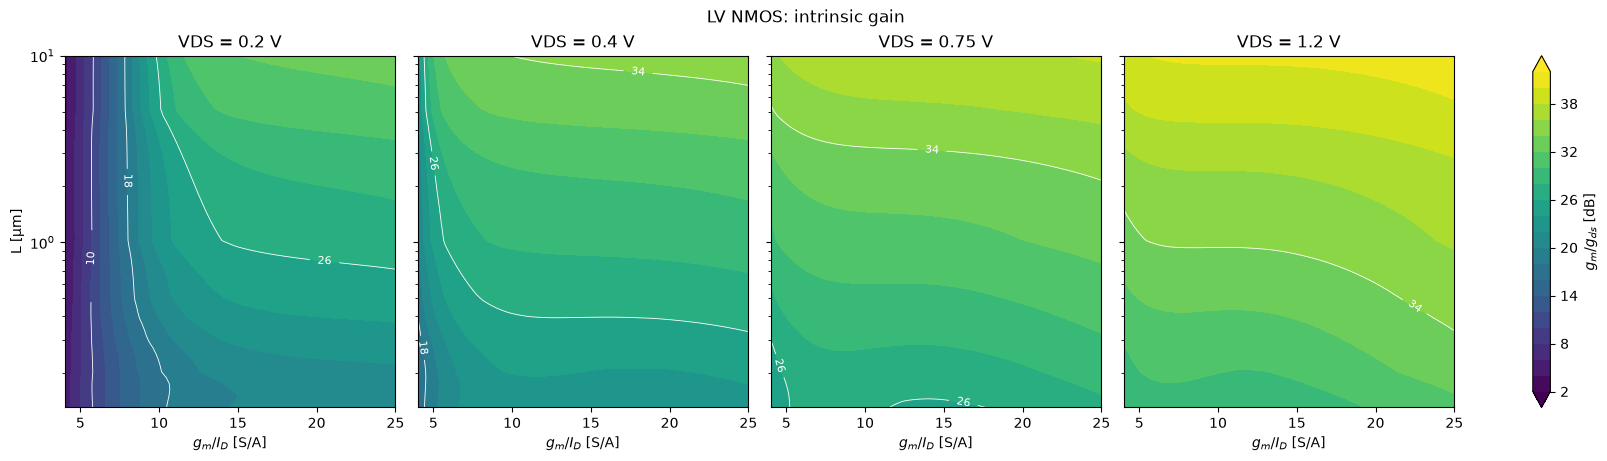

In [6]:
VDS_list = [0.2, 0.4, 0.75, 1.2]
g_dB = {vds: 20*np.log10(dev.lookup('GM_GDS', GM_ID=gm_id, L=L, VDS=vds)) for vds in VDS_list}

# Common levels from the overall range (below 0 dB the transistor is no amplifier anyway)
levels = nice_levels(np.clip([g_dB[v] for v in VDS_list], 0, None), 20)

fig, axs = plt.subplots(1, len(VDS_list), figsize=(16, 4.5), sharey=True, constrained_layout=True)
for ax, vds in zip(axs, VDS_list):
    cf = ax.contourf(X, Y, g_dB[vds], levels=levels, cmap='viridis', extend='both')
    cs = ax.contour(X, Y, g_dB[vds], levels=levels[::4], colors='white', linewidths=0.6)
    ax.clabel(cs, fmt='%.0f', fontsize=8)
    ax.set(title=f'VDS = {vds} V', xlabel='$g_m/I_D$ [S/A]', yscale='log')
axs[0].set_ylabel('L [µm]')
fig.colorbar(cf, ax=axs, label='$g_m/g_{ds}$ [dB]')
fig.suptitle(f'{dev_name}: intrinsic gain')
plt.show()

## 4b. Slider

Redraws the contour plot for the VDS set with the slider (updates when the slider is released).
The levels are fixed for the whole slider range, so the colors stay comparable while sliding.

In [7]:
from ipywidgets import interact, FloatSlider

VDS_min, VDS_max = 0.1, 1.5
g_ends = [20*np.log10(dev.lookup('GM_GDS', GM_ID=gm_id, L=L, VDS=v)) for v in np.linspace(VDS_min, VDS_max, 8)]
levels_slider = nice_levels(np.clip(g_ends, 0, None), 20)

@interact(vds=FloatSlider(value=0.75, min=VDS_min, max=VDS_max, step=0.05, description='VDS [V]', continuous_update=False))
def plot_gain(vds):
    g = dev.lookup('GM_GDS', GM_ID=gm_id, L=L, VDS=vds)
    fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
    cf = ax.contourf(X, Y, 20*np.log10(g), levels=levels_slider, cmap='viridis', extend='both')
    fig.colorbar(cf, ax=ax, label='$g_m/g_{ds}$ [dB]')
    ax.set(xlabel='$g_m/I_D$ [S/A]', ylabel='L [µm]', yscale='log', title=f'{dev_name}: intrinsic gain, VDS = {vds:.2f} V')
    plt.show()

interactive(children=(FloatSlider(value=0.75, continuous_update=False, description='VDS [V]', max=1.5, min=0.1…

# 5. Interactive Contour Plot (Plotly)

Hovering shows gm/ID, L and the value at the mouse position, dragging zooms in, double-click resets.

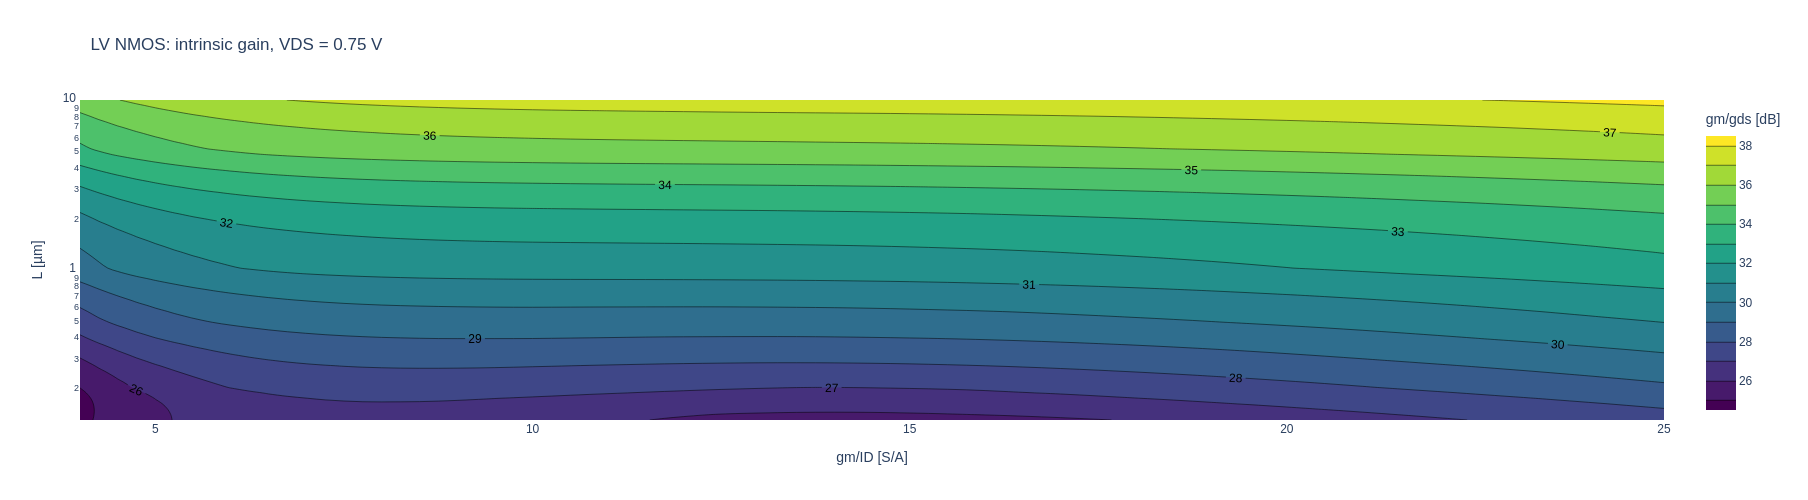

In [8]:
import plotly.graph_objects as go

fig = go.Figure(go.Contour(
    x=gm_id, y=L, z=gain_dB,
    colorscale='Viridis', colorbar=dict(title='gm/gds [dB]'),
    contours=dict(showlabels=True),
    customdata=fT,
    hovertemplate='gm/ID = %{x:.1f} S/A<br>L = %{y:.2f} µm<br>gm/gds = %{z:.1f} dB<br>fT = %{customdata:.3s}Hz<extra></extra>',
))
fig.update_layout(title=f'{dev_name}: intrinsic gain, VDS = {VDS} V',
                  xaxis_title='gm/ID [S/A]', yaxis_title='L [µm]', yaxis_type='log', width=800, height=500)
fig.show()

# 6. 3D Surface

Looks good, but reading values off it is harder than from a contour plot.
Matplotlib 3D axes have no log scale, hence log10(L).

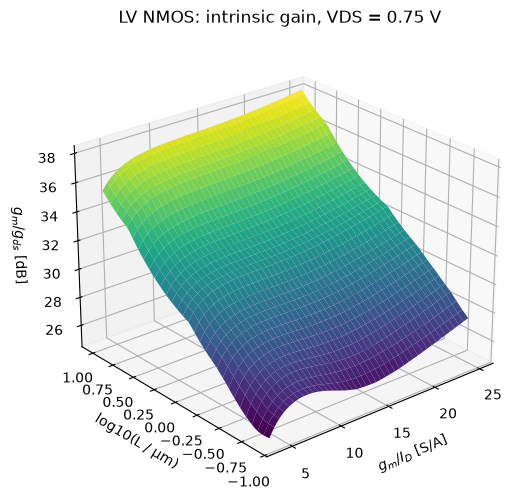

In [9]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(projection='3d')
ax.plot_surface(X, np.log10(Y), gain_dB, cmap='viridis')
ax.set(xlabel='$g_m/I_D$ [S/A]', ylabel='log10(L / µm)', zlabel='$g_m/g_{ds}$ [dB]',
       title=f'{dev_name}: intrinsic gain, VDS = {VDS} V')
ax.view_init(elev=25, azim=-130)
plt.show()

# From the Chart to a Size

Once gm/ID and L are chosen from the chart, W follows from the current density at that point.

In [10]:
gm_id_sel = 12     # [S/A]
L_sel = 0.5        # [µm]
ID_sel = 10e-6     # [A]

W_sel = ID_sel / dev.lookup('ID_W', GM_ID=gm_id_sel, L=L_sel, VDS=VDS)
gm_sel = gm_id_sel * ID_sel
print(f"W  = {float(W_sel):.2f} µm")
print(f"gm = {gm_sel*1e6:.1f} µS")
print(f"gm/gds = {float(dev.lookup('GM_GDS', GM_ID=gm_id_sel, L=L_sel, VDS=VDS)):.1f} V/V")
print(f"fT = {float(dev.lookup('GM_CGG', GM_ID=gm_id_sel, L=L_sel, VDS=VDS))/(2*np.pi)/1e9:.2f} GHz")

W  = 1.63 µm
gm = 120.0 µS
gm/gds = 30.1 V/V
fT = 3.01 GHz
